In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

In [ ]:
from google.colab import files
import pandas as pd

# Upload CSV file
uploaded = files.upload()

# Read the uploaded CSV file
df = pd.read_csv("dataKNN.csv")

# Display the data
print(df.head())

Saving dataKNN.csv to dataKNN.csv
   Debt_to_Income_Ratio  Credit_Score  Annual_Income  Total_Assets  \
0                0.3622           311       97917.97      15232.33   
1                0.7655           617       98278.93     138164.73   
2                0.6124           515       22981.27     261210.17   
3                0.5191           638       61874.04     138079.14   
4                0.2092           380      102743.78     316074.85   

   Credit_Risk_Rating  
0                   2  
1                   2  
2                   2  
3                   1  
4                   1  


In [ ]:
X = df[
    [
        'Debt_to_Income_Ratio',
        'Credit_Score',
        'Annual_Income',
        'Total_Assets'
    ]
]

y = df['Credit_Risk_Rating']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 4)
Testing data: (200, 4)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
k_range = range(1, 26)

cv_scores = []

for k in k_range:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric='minkowski',
        p=2
    )

    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_scores.append(scores.mean())

optimal_k = k_range[np.argmax(cv_scores)]

print("Optimal K:", optimal_k)

Optimal K: 6


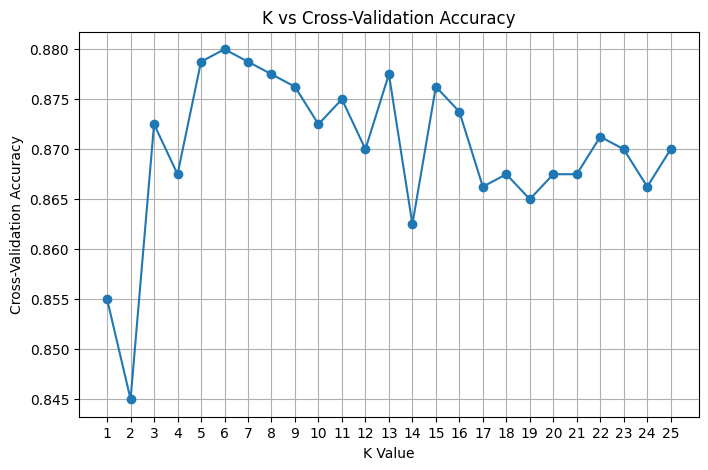

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_range,
    cv_scores,
    marker='o'
)

plt.xlabel("K Value")
plt.ylabel("Cross-Validation Accuracy")
plt.title("K vs Cross-Validation Accuracy")

plt.xticks(k_range)
plt.grid()

plt.show()

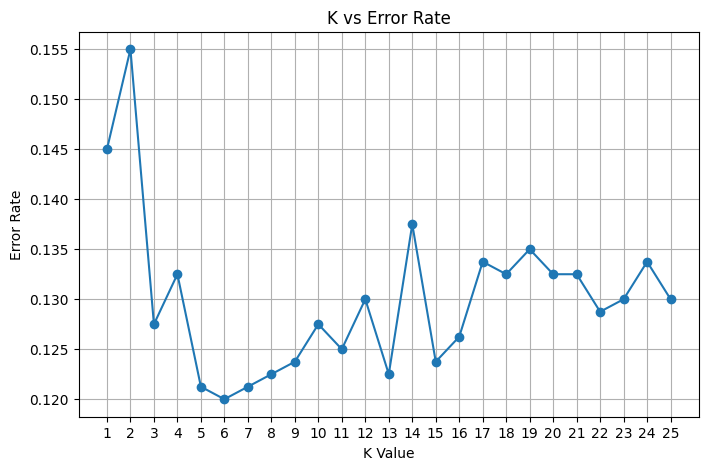

In [ ]:
error_rate = [1 - score for score in cv_scores]

plt.figure(figsize=(8, 5))

plt.plot(
    k_range,
    error_rate,
    marker='o'
)

plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("K vs Error Rate")

plt.xticks(k_range)
plt.grid()

plt.show()

In [ ]:
knn = KNeighborsClassifier(
    n_neighbors=optimal_k,
    weights='distance'
)

In [ ]:
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=6, weights='distance')

In [ ]:
y_pred = knn.predict(X_test_scaled)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.915
Accuracy (%): 91.5


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[62  5  0]
 [ 3 61  3]
 [ 0  6 60]]


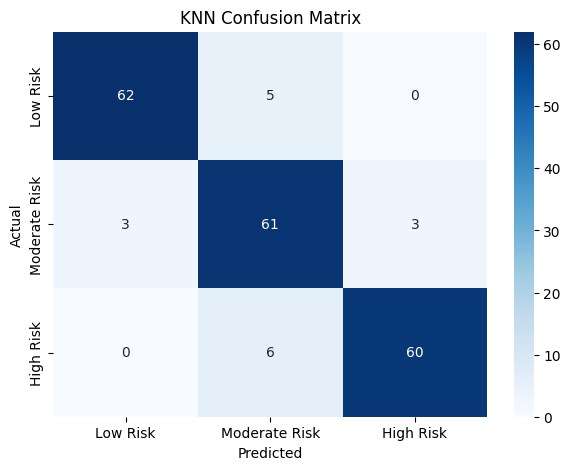

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Risk', 'Moderate Risk', 'High Risk'],
    yticklabels=['Low Risk', 'Moderate Risk', 'High Risk']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

In [ ]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'Low Risk',
            'Moderate Risk',
            'High Risk'
        ]
    )
)


Classification Report:
               precision    recall  f1-score   support

     Low Risk       0.95      0.93      0.94        67
Moderate Risk       0.85      0.91      0.88        67
    High Risk       0.95      0.91      0.93        66

     accuracy                           0.92       200
    macro avg       0.92      0.91      0.92       200
 weighted avg       0.92      0.92      0.92       200



In [ ]:
y_probs = knn.predict_proba(X_test_scaled)

In [ ]:
auc_score = roc_auc_score(
    y_test,
    y_probs,
    multi_class='ovr'
)

print("Multi-class ROC-AUC Score:", auc_score)

Multi-class ROC-AUC Score: 0.9832204323563318


In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

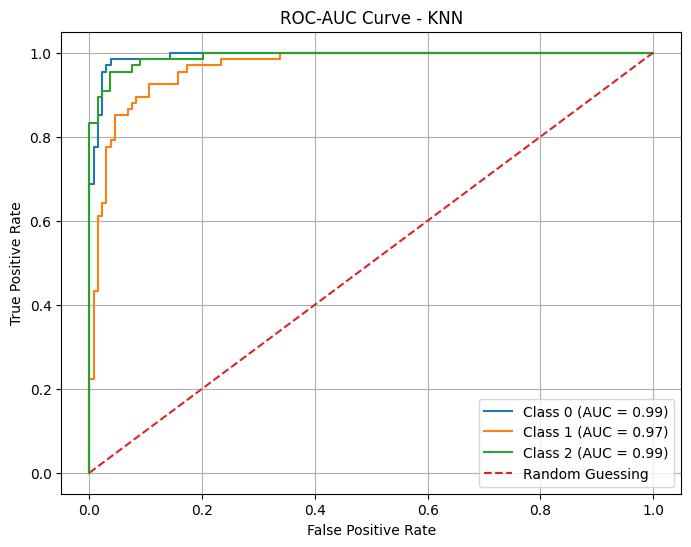

In [ ]:
# Convert the actual labels into binary form
y_test_binary = label_binarize(
    y_test,
    classes=[0, 1, 2]
)

# Calculate ROC curve for each class
plt.figure(figsize=(8, 6))

for i in range(3):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {i} (AUC = {roc_auc:.2f})"
    )

# Random guessing line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Guessing'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - KNN")

plt.legend()
plt.grid()

plt.show()